# Домашнее задание 1. Персональные top-10 рекомендации

**Кузнецов Иван Александрович**

В работе сравниваются ItemKNN, iALS, EASE, FM и timeSVD++ на Amazon Reviews 2023,
категория Clothing, Shoes and Jewelry. Рекомендуются товары, которые пользователь
раньше не оценивал. Релевантным считается товар с отложенной оценкой не ниже 4.

Для запуска нужен Python 3.11–3.13; работа выполнена на Python 3.13.0 и CPU.
Из корня проекта:

```bash
python -m pip install -r requirements.txt
jupyter lab experiments.ipynb
```

В Jupyter нужно выбрать **Restart Kernel and Run All Cells**. Запуск без интерфейса:

```bash
jupyter nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=-1 experiments.ipynb
```

Данные скачиваются ячейками ниже. При первом запуске нужны интернет и несколько ГБ
оперативной памяти. Файл взаимодействий занимает около 400 МБ. Поиск карточек может
потребовать прочитать до 18 ГБ по сети; сохраняются только нужные карточки.
После загрузки используются локальные файлы. Случайное зерно — 42.


In [1]:
import json
import random
import time
import platform
import numpy as np
import pandas as pd
import scipy
import torch
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits
from models.item_knn import ItemKNN
from models.ials import ImplicitALS
from models.ease import EASE
from models.fm import FactorizationMachine
from models.timesvdpp import TimeSVDPlusPlus
from pathlib import Path
import gzip
import shutil
import urllib.request
from scipy.sparse import csr_matrix
from collections import Counter
import hashlib
import http.client
import html
import re
import urllib.error

SOURCE = 'https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/benchmark/5core/rating_only/Clothing_Shoes_and_Jewelry.csv.gz'
START_DATE = pd.Timestamp('2018-01-01', tz='UTC')
END_DATE = pd.Timestamp('2023-10-01', tz='UTC')
TRAIN_END = pd.Timestamp('2020-01-01', tz='UTC')
VALID_END = pd.Timestamp('2021-01-12', tz='UTC')
MIN_USER_HISTORY = 5
MIN_ITEM_HISTORY = 5
SEED = 42
METADATA_REVISION = '2b6d039ed471f2ba5fd2acb718bf33b0a7e5598e'
METADATA_SOURCE = ('https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/'
                   f'resolve/{METADATA_REVISION}/raw/meta_categories/'
                   'meta_Clothing_Shoes_and_Jewelry.jsonl')
SNAPSHOT_YEAR = 2023

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(4)
torch.use_deterministic_algorithms(True)
thread_limit = threadpool_limits(limits=4)
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True})
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_rows', None)
print({'Python': platform.python_version(), 'numpy': np.__version__,
       'pandas': pd.__version__, 'scipy': scipy.__version__, 'torch': torch.__version__, 'seed': SEED})


{'Python': '3.13.0', 'numpy': '2.1.3', 'pandas': '2.3.3', 'scipy': '1.16.2', 'torch': '2.9.0+cpu', 'seed': 42}


## 1. Данные

Используется [Amazon Reviews 2023](https://amazon-reviews-2023.github.io/),
[официальная 5-core выборка](https://amazon-reviews-2023.github.io/data_processing/5core.html)
категории Clothing, Shoes and Jewelry. Загружается полный CSV категории,
разбиение на train, validation и test выполняется в этой работе.

Поля данных:

| Поле | Значение |
|---|---|
| `user_id` | Идентификатор пользователя |
| `parent_asin` | Идентификатор родительской карточки товара |
| `rating` | Оценка от 1 до 5 |
| `timestamp` | Время отзыва в миллисекундах Unix; переводится в UTC |

Взаимодействие означает оставленный отзыв. Это не обязательно подтверждённая покупка.
В исходном файле 23 102 537 взаимодействий, 2 524 981 пользователь и 714 957 товаров.
После отбора остаются 302 019 взаимодействий, 37 289 пользователей и 5000 товаров.

Для FM загружаются [карточки товаров Amazon Reviews 2023](https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023#for-item-metadata)
той же категории. Соединение выполняется по `parent_asin`. Используются магазин
`store`, категории и название. `store` — витрина магазина, а не обязательно бренд.
Дата `Date First Available` нужна для проверки доступности карточки.

Источник метаданных закреплён на ревизии `2b6d039ed471f2ba5fd2acb718bf33b0a7e5598e`.
Загрузчик ищет карточки всех товаров выбранного каталога, сохраняет прогресс
и продолжает чтение после обрыва. Повторный запуск использует готовый справочник.
Итоговые рейтинги товара, число отзывов, текущая цена и тексты будущих отзывов
в признаки не входят. Данные в GitHub не загружаются.


In [2]:
def download_data(path=Path('data/Clothing_Shoes_and_Jewelry.csv.gz')):
    path = Path(path)
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        temporary = path.with_suffix('.part')
        with urllib.request.urlopen(SOURCE, timeout=180) as src, temporary.open('wb') as dst:
            shutil.copyfileobj(src, dst)
        # Проверяем целостность архива до сохранения под окончательным именем.
        with gzip.open(temporary, 'rb') as stream:
            while stream.read(8 * 1024**2):
                pass
        temporary.replace(path)
    return path


def training_core(train, min_user_history=5, min_item_history=5):
    """Итеративно удаляет редкие вершины, используя только обучающие события."""
    core = train.copy()
    while True:
        previous_size = len(core)
        user_counts = core.user_id.value_counts()
        core = core[core.user_id.isin(user_counts[user_counts >= min_user_history].index)]
        item_counts = core.parent_asin.value_counts()
        core = core[core.parent_asin.isin(item_counts[item_counts >= min_item_history].index)]
        if len(core) == previous_size:
            return core.copy()


def prepare_data(path, top_items=5000):
    counts = pd.Series(dtype='int64')
    stats = {'raw_rows': 0, 'missing_rows': 0, 'invalid_rows': 0}
    raw_users, raw_items = set(), set()
    dtypes = {'user_id': 'str', 'parent_asin': 'str', 'rating': 'float32', 'timestamp': 'Int64'}
    def clean(chunk):
        chunk = chunk.dropna(subset=list(dtypes)).copy()
        chunk['timestamp'] = pd.to_datetime(chunk.timestamp, unit='ms', utc=True, errors='coerce')
        return chunk[chunk.rating.between(1, 5) & chunk.timestamp.between(START_DATE, END_DATE, inclusive='left')]
    for chunk in pd.read_csv(path, chunksize=500000, dtype=dtypes):
        stats['raw_rows'] += len(chunk)
        stats['missing_rows'] += int(chunk.isna().any(axis=1).sum())
        raw_users.update(chunk.user_id.dropna())
        raw_items.update(chunk.parent_asin.dropna())
        stats['invalid_rows'] += int((~chunk.rating.between(1, 5)).sum())
        frame = clean(chunk)
        freq = frame.loc[frame.timestamp < TRAIN_END, 'parent_asin'].value_counts()
        counts = counts.add(freq, fill_value=0)
    stats.update(raw_users=len(raw_users), raw_items=len(raw_items))
    del raw_users, raw_items
    # При равных частотах сортируем по ID; каталог строим только по train.
    catalog = counts.rename_axis('item').reset_index(name='count').sort_values(
        ['count', 'item'], ascending=[False, True]).head(top_items)['item']
    pieces = []
    for chunk in pd.read_csv(path, chunksize=500000, dtype=dtypes):
        chunk = clean(chunk)
        pieces.append(chunk[chunk.parent_asin.isin(catalog)])
    frame = pd.concat(pieces, ignore_index=True)
    # Будущая повторная оценка не должна перезаписывать событие из train.
    stats['catalog_rows_before_dedup'] = len(frame)
    frame = frame.sort_values(['timestamp', 'user_id', 'parent_asin'], kind='stable')
    frame = frame.drop_duplicates(['user_id', 'parent_asin'], keep='first')
    stats['duplicate_pairs_removed'] = stats['catalog_rows_before_dedup'] - len(frame)
    initial_train = frame[frame.timestamp < TRAIN_END]
    core = training_core(initial_train, MIN_USER_HISTORY, MIN_ITEM_HISTORY)
    stats['train_rows_before_core'] = len(initial_train)
    stats['train_rows_removed_by_core'] = len(initial_train) - len(core)
    frame = frame[frame.user_id.isin(core.user_id.unique()) &
                  frame.parent_asin.isin(core.parent_asin.unique())].copy()
    assert 100000 <= len(frame) <= 2000000, f'Недопустимое итоговое число взаимодействий: {len(frame)}'
    train = frame[frame.timestamp < TRAIN_END].copy()
    users = sorted(train.user_id.unique())
    items = sorted(train.parent_asin.unique())
    assert len(users) >= 1000 and len(items) >= 1000
    user_map, item_map = dict(zip(users, range(len(users)))), dict(zip(items, range(len(items))))
    frame['u'] = frame.user_id.map(user_map).astype(int)
    frame['i'] = frame.parent_asin.map(item_map).astype(int)
    train = frame[frame.timestamp < TRAIN_END].copy()
    valid = frame[(frame.timestamp >= TRAIN_END) & (frame.timestamp < VALID_END)].copy()
    test = frame[frame.timestamp >= VALID_END].copy()
    stats.update(final_rows=len(frame), final_users=len(users), final_items=len(items),
                 eligible_train_users=len(users), min_user_train_history=MIN_USER_HISTORY,
                 min_item_train_history=MIN_ITEM_HISTORY, requested_items=top_items)
    return frame, train, valid, test, stats


In [3]:
data_path = download_data()
print('Источник:', SOURCE)
print('Локальный файл:', data_path, 'МБ:', round(data_path.stat().st_size / 1024**2, 1))
data, train, valid, test, data_stats = prepare_data(data_path, top_items=5000)
display(pd.Series(data_stats, name='Значение').to_frame())
display(data[['user_id', 'parent_asin', 'rating', 'timestamp']].head())

Источник: https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/benchmark/5core/rating_only/Clothing_Shoes_and_Jewelry.csv.gz
Локальный файл: data\Clothing_Shoes_and_Jewelry.csv.gz МБ: 378.6


,Значение
raw_rows,23102537
missing_rows,0
invalid_rows,0
raw_users,2524981
raw_items,714957
catalog_rows_before_dedup,3917610
duplicate_pairs_removed,0
train_rows_before_core,1655209
train_rows_removed_by_core,1414517
final_rows,302019


,user_id,parent_asin,rating,timestamp
224879,AGVBFCBBYALGEUAU3ZOSVL7W74JQ,B0BCHL66FT,5.0,2018-01-01 00:11:27.878000+00:00
706444,AEZK47T3TRAKY4MBKLHCHD4Z7CJA,B0BHN3QR2S,5.0,2018-01-01 00:54:10.877000+00:00
706445,AEZK47T3TRAKY4MBKLHCHD4Z7CJA,B0084AVW7I,5.0,2018-01-01 01:06:27.022000+00:00
140096,AHWLEO26BRWNJGKBQGNWC52LYRJQ,B07YVL8QKM,4.0,2018-01-01 01:33:07.650000+00:00
2162125,AEDAWXMOFZW3KYZC2NQZA3O3XKBQ,B09YJLQ3FP,5.0,2018-01-01 01:54:10.843000+00:00


## 2. Подготовка и EDA

Оставлен период с 01.01.2018 до 01.10.2023, непустые идентификаторы и время,
оценки от 1 до 5. Для повторных пар пользователь–товар сохраняется первое событие,
чтобы будущая оценка не заменила прошлую.

По событиям до 01.01.2020 выбираются 5000 самых популярных товаров. Равные частоты
разрешаются по ID. Ограничение каталога позволяет обучить плотную модель EASE
с доступной памятью.

В train последовательно удаляются пользователи с менее чем пятью разными товарами
и товары с менее чем пятью пользователями. Фильтрация повторяется до устойчивого
состава: удаление товара может сократить историю пользователя. Validation и test
ограничиваются полученными ID. Будущая активность для включения в выборку не требуется.

Такой отбор оставляет достаточно событий для обучения персональных рекомендаций.
В train в среднем 6,45 товара на пользователя, медиана — 6, минимум — 5.
Ниже проверяются пропуски, дубликаты, активность, популярность, оценки,
разреженность и заполненность метаданных.


In [4]:
def matrix(frame, shape):
    result = csr_matrix((np.ones(len(frame), dtype=np.float32), (frame.u, frame.i)), shape=shape)
    result.sum_duplicates()
    result.data[:] = 1
    return result


def historical_features(train, shape, cutoff=TRAIN_END):
    """Агрегаты истории, вычисленные только по train на момент cutoff."""
    if train.timestamp.isna().any() or not train.timestamp.lt(cutoff).all():
        raise ValueError('В агрегаты истории попали события без времени или не раньше границы обучения')
    features = []
    names = ['log_count', 'mean_rating', 'days_since_last']
    for key, size in [('u', shape[0]), ('i', shape[1])]:
        agg = train.groupby(key).agg(count=('rating', 'size'), mean=('rating', 'mean'), last=('timestamp', 'max')).reindex(range(size))
        values = np.column_stack([np.log1p(agg['count']), agg['mean'],
                                  np.log1p((cutoff - agg['last']).dt.total_seconds() / 86400)])
        values = (values - values.mean(0)) / np.maximum(values.std(0), 1e-6)
        assert np.isfinite(values).all()
        features.append(values.astype(np.float32))
    return (*features, names)


Пропуски после очистки: {'user_id': 0, 'parent_asin': 0, 'rating': 0, 'timestamp': 0, 'u': 0, 'i': 0}
Дубли пар после очистки: 0
Размер матрицы: (37289, 5000) train nnz: 240692
Разреженность train: 0.9987090455630346
Длина train-истории:


,user_activity,item_popularity
count,37289.000000,5000.000000
mean,8.099413,60.403800
std,3.835019,82.978866
min,5.000000,6.000000
25%,6.000000,30.000000
50%,7.000000,43.000000
75%,9.000000,68.000000
max,92.000000,4492.000000


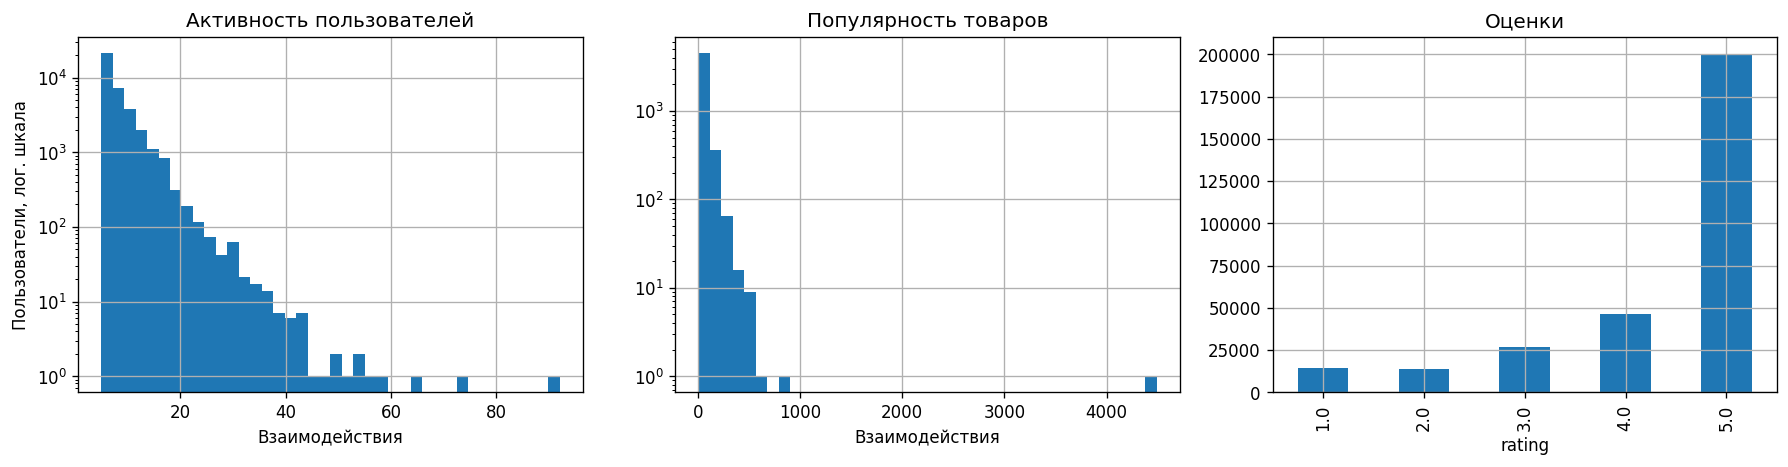

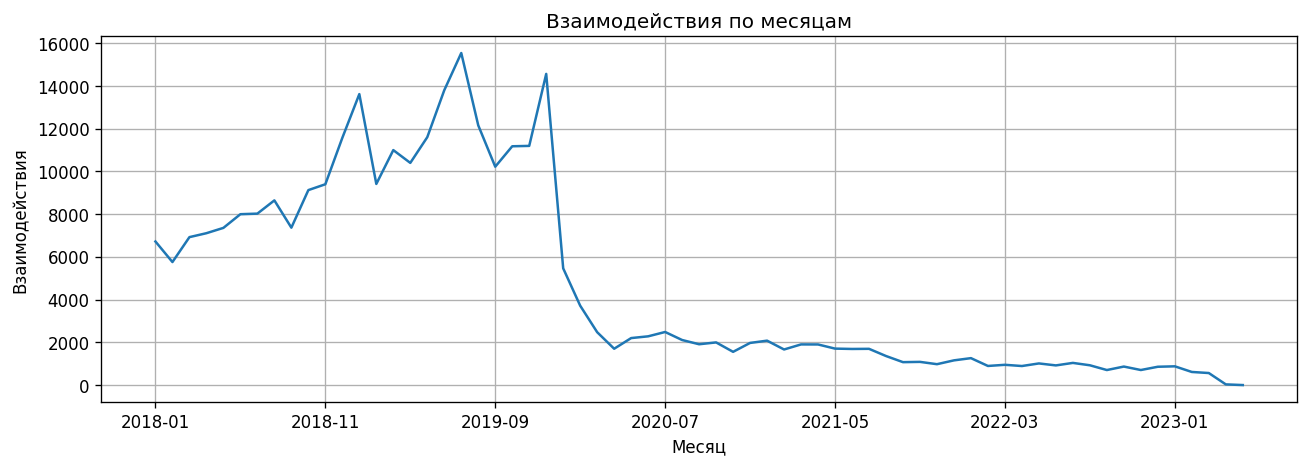

,Товаров у пользователя,Пользователей у товара
count,37289.000000,5000.000000
mean,6.454772,48.138400
std,2.339701,60.342385
min,5.000000,5.000000
25%,5.000000,24.000000
50%,6.000000,35.000000
75%,7.000000,54.000000
max,48.000000,3009.000000


In [5]:
print('Пропуски после очистки:', data.isna().sum().to_dict())
print('Дубли пар после очистки:', data.duplicated(['u', 'i']).sum())
activity = data.groupby('u').size()
popularity = data.groupby('i').size()
display(pd.DataFrame({'user_activity': activity.describe(), 'item_popularity': popularity.describe()}))
shape = (train.u.nunique(), train.i.nunique())
X = matrix(train, shape)
print('Размер матрицы:', shape, 'train nnz:', X.nnz)
print('Разреженность train:', 1 - X.nnz / np.prod(shape))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(activity, bins=40, log=True); axes[0].set(title='Активность пользователей', xlabel='Взаимодействия', ylabel='Пользователи, лог. шкала')
axes[1].hist(popularity, bins=40, log=True); axes[1].set(title='Популярность товаров', xlabel='Взаимодействия')
data.rating.value_counts().sort_index().plot.bar(ax=axes[2], title='Оценки')
plt.tight_layout(); plt.show()
monthly = data.groupby(data.timestamp.dt.strftime('%Y-%m')).size()
monthly.plot(title='Взаимодействия по месяцам', ylabel='Взаимодействия', xlabel='Месяц')
plt.tight_layout(); plt.show()
print('Длина train-истории:')
display(pd.DataFrame({'Товаров у пользователя': pd.Series(np.diff(X.indptr)).describe(),
    'Пользователей у товара': pd.Series(np.diff(X.tocsc().indptr)).describe()}))
train_lengths = np.diff(X.indptr)
assert train_lengths.min() >= 5
assert np.diff(X.tocsc().indptr).min() >= 5


In [6]:
def _text(value):
    if not isinstance(value, str):
        return ''
    return re.sub(r'\s+', ' ', html.unescape(value)).strip()


def load_metadata(item_ids, path=Path('data/item_metadata_2023.json')):
    """Ищет карточки каталога, переиспользуя известные ID из той же версии источника."""
    path = Path(path)
    item_ids = list(item_ids)
    if not item_ids or len(set(item_ids)) != len(item_ids):
        raise ValueError('Каталог должен содержать непустой список уникальных ID')
    digest = hashlib.sha256(json.dumps(sorted(item_ids)).encode()).hexdigest()
    cached = {}
    reused_records = 0
    seed_source = None
    if path.exists():
        candidate = json.loads(path.read_text(encoding='utf-8'))
        if candidate.get('source') == METADATA_SOURCE:
            cached = candidate
            expected = cached.get('records_sha256')
            if expected and expected != _json_digest(cached['records']):
                raise ValueError('Контрольная сумма локальных карточек не совпадает')
            if cached.get('segments_sha256') and cached['segments_sha256'] != _json_digest(cached['source_segments']):
                raise ValueError('Контрольная сумма списка фрагментов не совпадает')
            if cached.get('catalog_sha256') != digest:
                reused_records = len(set(item_ids) & cached['records'].keys())
                seed_source = {'catalog_sha256': cached.get('catalog_sha256'),
                               'records_sha256': cached.get('records_sha256'),
                               'source_rows': cached.get('source_rows'),
                               'source_bytes': cached.get('source_bytes')}
                cached = {'records': cached['records'], 'source_total_bytes': cached.get('source_total_bytes')}
        if cached.get('scan_complete'):
            missing = sorted(set(item_ids) - cached['records'].keys())
            reason = cached.get('completion_reason')
            if (missing != cached.get('missing_item_ids')
                    or reason not in ['all_catalog_items_found', 'source_exhausted']
                    or (reason == 'all_catalog_items_found' and missing)
                    or (reason == 'source_exhausted' and cached['source_bytes'] != cached['source_total_bytes'])):
                raise ValueError('Сохранённый результат поиска противоречит признаку завершения')
            return _metadata_table(item_ids, cached['records']), cached
    records = cached.get('records', {})
    selected = set(item_ids)
    missing_ids = selected - records.keys()
    reused_records = cached.get('reused_records_count', reused_records)
    seed_source = cached.get('seed_source', seed_source)
    rows, offset = cached.get('source_rows', 0), cached.get('source_bytes', 0)
    segments = cached.get('source_segments', [])
    if offset and not segments:
        if not cached.get('prefix_sha256'):
            raise ValueError('У сохранённого фрагмента нет контрольной суммы')
        segments = [{'start': 0, 'end': offset, 'rows_end': rows, 'sha256': cached['prefix_sha256']}]
    total = cached.get('source_total_bytes')
    segment_start, segment_digest = offset, hashlib.sha256()

    def save(reason=None):
        nonlocal segment_start, segment_digest
        if offset > segment_start:
            segments.append({'start': segment_start, 'end': offset,
                             'rows_end': rows, 'sha256': segment_digest.hexdigest()})
            segment_start, segment_digest = offset, hashlib.sha256()
        manifest = {'source': METADATA_SOURCE, 'snapshot_year': SNAPSHOT_YEAR,
                    'source_revision': METADATA_REVISION, 'catalog_sha256': digest,
                    'source_rows': rows, 'source_bytes': offset, 'source_total_bytes': total,
                    'source_segments': segments, 'segments_sha256': _json_digest(segments),
                    'records_sha256': _json_digest(records), 'records': records,
                    'scan_complete': reason is not None, 'completion_reason': reason,
                    'missing_item_ids': sorted(missing_ids),
                    'reused_records_count': reused_records, 'seed_source': seed_source}
        path.parent.mkdir(parents=True, exist_ok=True)
        temporary = path.with_suffix('.part')
        temporary.write_text(json.dumps(manifest, ensure_ascii=False, indent=1), encoding='utf-8')
        temporary.replace(path)
        return manifest

    if missing_ids:
        save()
    failures = 0
    while missing_ids:
        try:
            request = urllib.request.Request(METADATA_SOURCE, headers={'Range': f'bytes={offset}-'})
            with urllib.request.urlopen(request, timeout=180) as response:
                content_range = response.headers.get('Content-Range', '')
                if offset:
                    match = re.fullmatch(r'bytes (\d+)-(\d+)/(\d+)', content_range)
                    if response.status != 206 or not match or int(match[1]) != offset:
                        raise ValueError('Сервер не подтвердил продолжение с нужного байта')
                    total = int(match[3])
                else:
                    total = (int(content_range.split('/')[-1]) if content_range
                             else int(response.headers.get('Content-Length', 0)) or None)
                print(f'Метаданные: продолжаем с {rows:,} карточек, найдено {len(selected)-len(missing_ids)}/{len(selected)}', flush=True)
                while missing_ids:
                    line = response.readline()
                    if not line:
                        if total is None or offset != total:
                            raise OSError('Источник оборвался до подтверждённого конца файла')
                        manifest = save('source_exhausted')
                        return _metadata_table(item_ids, records), manifest
                    if not line.endswith(b'\n') and total is not None and offset + len(line) != total:
                        raise OSError('Получена неполная строка JSONL')
                    row = json.loads(line)
                    asin = row.get('parent_asin')
                    if asin in missing_ids:
                        categories = row.get('categories') or []
                        if categories and isinstance(categories[0], list):
                            categories = categories[0]
                        categories = [_text(c) for c in categories if _text(c)]
                        details = row.get('details') or {}
                        records[asin] = {'title': _text(row.get('title')), 'store': _text(row.get('store')),
                                         'category': categories[-1] if categories else '',
                                         'category_path': categories,
                                         'date_first_available': _text(details.get('Date First Available'))}
                        missing_ids.remove(asin)
                    segment_digest.update(line)
                    offset += len(line)
                    rows += 1
                    failures = 0
                    if rows % 25000 == 0:
                        save()
                    if rows % 100000 == 0:
                        print(f'Прочитано {rows:,} карточек; {offset / 1024**3:.2f} ГБ; '
                              f'найдено {len(selected)-len(missing_ids)}/{len(selected)} товаров', flush=True)
        except urllib.error.HTTPError as error:
            if error.code == 416 and total == offset:
                manifest = save('source_exhausted')
                return _metadata_table(item_ids, records), manifest
            save()
            if error.code not in [408, 429, 500, 502, 503, 504] or failures >= 3:
                raise
            failures += 1
            time.sleep(3 * failures)
        except (OSError, EOFError, http.client.IncompleteRead):
            save()
            if failures >= 3:
                raise
            failures += 1
            time.sleep(3 * failures)
    manifest = save('all_catalog_items_found')
    return _metadata_table(item_ids, records), manifest


def _json_digest(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, ensure_ascii=False).encode('utf-8')).hexdigest()


def _metadata_table(item_ids, records):
    rows = []
    for item_id in item_ids:
        entry = records.get(item_id, {})
        rows.append({'parent_asin': item_id, 'title': entry.get('title', ''),
                     'store': entry.get('store', ''), 'category': entry.get('category', ''),
                     'category_path': entry.get('category_path', []),
                     'date_first_available': entry.get('date_first_available', ''),
                     'metadata_present': item_id in records})
    return pd.DataFrame(rows)


def metadata_features(metadata, cutoff, max_levels=32, title_bins=0, hierarchical=False):
    """Кодирует карточки; словари и текстовые признаки не используют отзывы holdout."""
    metadata = metadata.copy()
    first_dates = pd.to_datetime(metadata.date_first_available, format='mixed', utc=True, errors='coerce')
    unavailable = first_dates.ge(cutoff)
    metadata.loc[unavailable, ['store', 'category', 'title']] = ''
    for index in metadata.index[unavailable]:
        metadata.at[index, 'category_path'] = []
    usable = metadata.metadata_present & ~unavailable
    columns, names = [usable.to_numpy(dtype=np.float32)], ['metadata_usable']
    for field in ['store', 'category']:
        counts = Counter(value for value in metadata[field] if value)
        common = [value for value, count in sorted(counts.items(), key=lambda p: (-p[1], p[0]))[:max_levels]]
        vocabulary = common + ['<OTHER>', '<MISSING>']
        mapping = {value: index for index, value in enumerate(vocabulary)}
        values = np.zeros((len(metadata), len(vocabulary)), dtype=np.float32)
        for row, value in enumerate(metadata[field]):
            level = value if value in mapping else ('<OTHER>' if value else '<MISSING>')
            values[row, mapping[level]] = 1
        columns.extend(values.T)
        names.extend(f'{field}={level}' for level in vocabulary)
    if hierarchical:
        paths = [[f'{depth}:{label}' for depth, label in enumerate(path) if depth > 0]
                 for path in metadata.category_path]
        counts = Counter(token for path in paths for token in set(path))
        levels = [value for value, _ in sorted(counts.items(), key=lambda p: (-p[1], p[0]))[:max_levels]]
        levels += ['<OTHER>', '<MISSING>']
        mapping = {value: index for index, value in enumerate(levels)}
        values = np.zeros((len(metadata), len(levels)), dtype=np.float32)
        for row, path in enumerate(paths):
            indices = {mapping.get(token, mapping['<OTHER>']) for token in path} or {mapping['<MISSING>']}
            values[row, list(indices)] = 1 / np.sqrt(len(indices))
        columns.extend(values.T)
        names.extend(f'category_path={level}' for level in levels)
    if title_bins:
        stopwords = {'the', 'and', 'for', 'with', 'of', 'to', 'in', 'on', 'by', 'at', 'from', 'new'}
        values = np.zeros((len(metadata), title_bins), dtype=np.float32)
        for row, title in enumerate(metadata.title):
            for token in set(re.findall(r'[a-z]{2,}', title.lower())) - stopwords:
                index = int.from_bytes(hashlib.blake2b(token.encode(), digest_size=8).digest(), 'little') % title_bins
                values[row, index] += 1
            norm = np.linalg.norm(values[row])
            if norm:
                values[row] /= norm
        columns.extend(values.T)
        names.extend(f'title_hash={index}' for index in range(title_bins))
    return np.column_stack(columns).astype(np.float32), names


,Набор,Признаков товара
0,structured,72
1,rich,330


,Значение
Товаров в каталоге,5000
Найдена карточка,5000
Карточка отсутствует в источнике,0
Заполнено название,5000
Заполнен магазин,4998
Заполнена категория,5000
Уникальных магазинов,2101
Уникальных конечных категорий,416
"Дата появления не раньше границы train, признаки отключены",1170
Дата появления отсутствует или не распознана,175


,parent_asin,title,store,category,date_first_available
0,B000ARJGC6,Skechers Sport Men's Energy Downforce Lace-Up ...,Skechers,Fashion Sneakers,"September 14, 2005"
1,B000ARKMQA,Skechers Sport Women's Premium Sneaker,Skechers,Fashion Sneakers,"August 1, 2004"
2,B000BVZYYA,Propet Mens LifeWalker Strap Walking Walking S...,Propét,Fashion Sneakers,"June 15, 2009"
3,B000DZZFUW,Sanuk Yoga Mat,Sanuk,Flip-Flops,"December 12, 2002"
4,B000EQS1JW,Citizen Men's Eco-Drive Weekender Garrison Fie...,Citizen,Wrist Watches,"March 15, 2005"


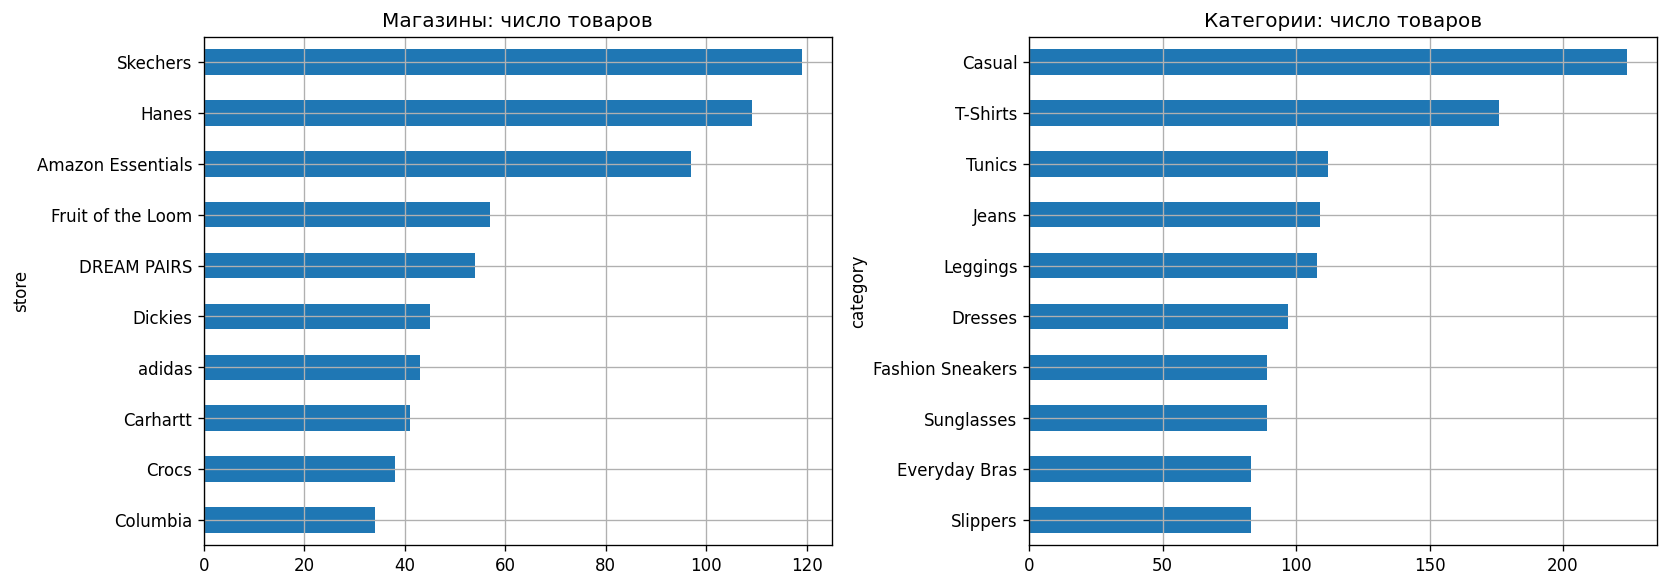

In [7]:
user_features, historical_item_features, feature_names = historical_features(train, shape)

catalog_ids = train[['i', 'parent_asin']].drop_duplicates().sort_values('i').parent_asin.tolist()
item_metadata, metadata_manifest = load_metadata(catalog_ids)
assert item_metadata.parent_asin.tolist() == catalog_ids
assert metadata_manifest['snapshot_year'] == 2023
assert metadata_manifest['scan_complete']
assert set(metadata_manifest['missing_item_ids']) == set(catalog_ids) - set(metadata_manifest['records'])
feature_recipes = {
    'structured': {'max_levels': 32, 'title_bins': 0, 'hierarchical': False},
    'rich': {'max_levels': 64, 'title_bins': 128, 'hierarchical': True},
}
item_feature_sets, feature_names_per_set = {}, {}
for name, recipe in feature_recipes.items():
    content, names = metadata_features(item_metadata, cutoff=TRAIN_END, **recipe)
    item_feature_sets[name] = np.column_stack([historical_item_features, content]).astype(np.float32)
    feature_names_per_set[name] = names
    assert np.isfinite(item_feature_sets[name]).all()
assert np.isfinite(user_features).all()
display(pd.DataFrame([{'Набор': name, 'Признаков товара': values.shape[1]}
    for name, values in item_feature_sets.items()]))

first_available = pd.to_datetime(item_metadata.date_first_available, format='mixed', utc=True, errors='coerce')
metadata_summary = pd.Series({
    'Товаров в каталоге': len(item_metadata),
    'Найдена карточка': int(item_metadata.metadata_present.sum()),
    'Карточка отсутствует в источнике': int((~item_metadata.metadata_present).sum()),
    'Заполнено название': int(item_metadata.title.ne('').sum()),
    'Заполнен магазин': int(item_metadata.store.ne('').sum()),
    'Заполнена категория': int(item_metadata.category.ne('').sum()),
    'Уникальных магазинов': item_metadata.loc[item_metadata.store.ne(''), 'store'].nunique(),
    'Уникальных конечных категорий': item_metadata.loc[item_metadata.category.ne(''), 'category'].nunique(),
    'Дата появления не раньше границы train, признаки отключены': int(first_available.ge(TRAIN_END).sum()),
    'Дата появления отсутствует или не распознана': int(first_available.isna().sum()),
})
with pd.option_context('display.max_colwidth', None):
    display(metadata_summary.to_frame('Значение'))
display(item_metadata[['parent_asin', 'title', 'store', 'category', 'date_first_available']].head(5))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
item_metadata.loc[item_metadata.store.ne(''), 'store'].value_counts().head(10).sort_values().plot.barh(ax=axes[0], title='Магазины: число товаров')
item_metadata.loc[item_metadata.category.ne(''), 'category'].value_counts().head(10).sort_values().plot.barh(ax=axes[1], title='Категории: число товаров')
plt.tight_layout(); plt.show()

В исходном CSV пропусков и оценок вне диапазона 1–5 не обнаружено.
После очистки повторных пар нет. Матрица train разрежена на 99,87%:
большинство пар пользователь–товар не наблюдалось. В train медиана числа пользователей
на товар — 35, максимум — 3009, поэтому популярность товаров заметно различается.
Оценки смещены вверх: около 66,4% отзывов имеют оценку 5, ещё 15,3% — оценку 4.

Найдены карточки всех 5000 товаров. Название и категория заполнены у всех,
магазин отсутствует у двух товаров. Для 1170 карточек внешние признаки отключены
на границе train из-за даты появления; у 175 дата не указана или не распознана.


## 3. Протокол оценки

Используется общее временное разбиение в UTC:

| Часть | Период |
|---|---|
| Train | [01.01.2018, 01.01.2020) |
| Validation | [01.01.2020, 12.01.2021) |
| Test | [12.01.2021, 01.10.2023) |

Границы выбраны по распределению времени и объёмам частей до подбора моделей,
с ориентиром 80/10/10. Каталог и пользователи определяются только по train.
Новые пользователи и товары исключаются; качество для них в работе не оценивается.

Все модели ранжируют весь каталог из 5000 товаров. В validation исключаются
train-товары пользователя, в test — товары из train и validation, включая низкие
оценки. Оцениваются пользователи хотя бы с одним доступным релевантным товаром
соответствующей части. Внутри каждой части пользователи, кандидаты и маски одинаковы
для всех моделей. При равных прогнозах порядок определяется индексом товара.

**Основная метрика для подбора — NDCG@10.** Она учитывает место релевантных товаров
в списке: $DCG@10=\sum_{r=1}^{10}rel_r/\log_2(r+1)$,
$NDCG@10=DCG@10/IDCG@10$, где IDCG — результат идеального порядка.
**Recall@10** — число найденных релевантных товаров, делённое на общее число
доступных релевантных товаров пользователя. Обе метрики усредняются по пользователям.
Первая оценивает порядок, вторая — полноту рекомендаций. Порог релевантности для
всех моделей одинаков: rating ≥ 4.

Настройки выбираются на validation при обучении только на train. После выбора
каждая модель заново обучается на train+validation и оценивается на test.
Агрегаты истории и признаки FM пересчитываются на соответствующей границе.
События test не используются при обучении и подборе.

Для timeSVD++ время рекомендации фиксируется на начале validation или test.
Реальное время будущего отзыва модели не передаётся. Неявная история содержит
только события до начала оцениваемого периода.

Проверки ниже контролируют временные границы, отсутствие пересечений пар,
известность ID и исключение уже известных товаров.


In [8]:
def relevance(frame, shape, seen):
    truth = matrix(frame[frame.rating >= 4], shape)
    truth = truth - truth.multiply(seen)
    truth.eliminate_zeros()
    return truth


def audit_split(data, train, valid, test, shape):
    """Проверяет временные границы, отсутствие пересечений и состав кандидатов."""
    assert all(len(part) > 0 for part in (train, valid, test))
    assert len(data) == len(train) + len(valid) + len(test)
    assert set(data.index) == set(train.index) | set(valid.index) | set(test.index)
    assert data.timestamp.ge(START_DATE).all() and data.timestamp.lt(END_DATE).all()
    assert train.timestamp.lt(TRAIN_END).all()
    assert valid.timestamp.ge(TRAIN_END).all() and valid.timestamp.lt(VALID_END).all()
    assert test.timestamp.ge(VALID_END).all()
    assert test.timestamp.lt(END_DATE).all()
    train_users, train_items = set(train.u), set(train.i)
    pair_sets = [set(zip(part.u, part.i)) for part in (train, valid, test)]
    assert not pair_sets[0] & pair_sets[1]
    assert not pair_sets[0] & pair_sets[2]
    assert not pair_sets[1] & pair_sets[2]
    assert data[['u', 'i']].duplicated().sum() == 0
    for part in (train, valid, test):
        assert set(part.u) <= train_users and set(part.i) <= train_items
    assert train_users == set(range(shape[0])) and train_items == set(range(shape[1]))
    assert train.groupby('u').size().min() >= MIN_USER_HISTORY
    assert train.groupby('i').size().min() >= MIN_ITEM_HISTORY
    X = matrix(train, shape)
    seen_test = matrix(pd.concat([train, valid]), shape)
    valid_truth, test_truth = relevance(valid, shape, X), relevance(test, shape, seen_test)
    assert valid_truth.multiply(X).nnz == 0
    assert test_truth.multiply(seen_test).nnz == 0
    for truth, frame in [(valid_truth, valid), (test_truth, test)]:
        assert truth.nnz == (frame.rating >= 4).sum()
        assert (np.diff(truth.indptr) > 0).sum() > 0
    assert (shape[1] - np.diff(seen_test.indptr) >= 10).all()
    return pd.DataFrame([
        {'Проверка': 'Временные границы UTC соблюдены', 'Пройдена': True},
        {'Проверка': 'События полностью разделены между тремя частями', 'Пройдена': True},
        {'Проверка': 'Пары пользователь–товар не пересекаются', 'Пройдена': True},
        {'Проверка': 'Все ID оценки известны в train', 'Пройдена': True},
        {'Проверка': f'У каждого пользователя минимум {MIN_USER_HISTORY} train-товаров', 'Пройдена': True},
        {'Проверка': f'У каждого товара минимум {MIN_ITEM_HISTORY} train-пользователей', 'Пройдена': True},
        {'Проверка': 'Релевантны только неизвестные товары с оценкой >= 4', 'Пройдена': True},
        {'Проверка': 'Для каждого пользователя есть минимум 10 кандидатов', 'Пройдена': True},
    ])


def recommend(model, users, seen, k=10):
    scores = np.asarray(model.score(users), dtype=np.float32).copy()
    if not np.isfinite(scores).all():
        raise ValueError('Прогнозы модели содержат NaN или бесконечность')
    r, c = seen[users].nonzero()
    scores[r, c] = -np.inf
    if np.any(np.isfinite(scores).sum(1) < k):
        raise ValueError('Недостаточно неизвестных пользователю товаров-кандидатов')
    # При равных прогнозах порядок определяется индексом товара.
    return np.argsort(-scores, axis=1, kind='stable')[:, :k]


def evaluate(model, truth, seen, k=10, batch_size=256, return_per_user=False):
    users = np.flatnonzero(np.diff(truth.indptr) > 0)
    if not len(users):
        raise ValueError('Нет пользователей с доступными релевантными товарами')
    discounts = 1 / np.log2(np.arange(2, k + 2))
    recalls, ndcgs = [], []
    for start in range(0, len(users), batch_size):
        batch = users[start:start + batch_size]
        recs = recommend(model, batch, seen, k)
        for user, rec in zip(batch, recs):
            relevant = truth[user].indices
            hits = np.isin(rec, relevant)
            recalls.append(hits.sum() / len(relevant))
            ndcgs.append(float(hits @ discounts / discounts[:min(k, len(relevant))].sum()))
    result = {f'NDCG@{k}': float(np.mean(ndcgs)), f'Recall@{k}': float(np.mean(recalls)), 'users': len(users)}
    if return_per_user:
        return result, pd.DataFrame({'user': users, f'NDCG@{k}': ndcgs, f'Recall@{k}': recalls})
    return result


class PopularityBaseline:
    """Неперсонализированный ориентир: частоты товаров в обучающей истории."""

    def fit(self, interactions):
        self.popularity = np.asarray(interactions.sum(axis=0)).ravel().astype(np.float32)
        return self

    def score(self, users):
        return np.broadcast_to(self.popularity, (len(users), len(self.popularity)))


def random_expected_metrics(truth, seen, k=10):
    """Точное ожидание метрик равномерного случайного top-k среди неизвестных товаров."""
    relevant_counts = np.diff(truth.indptr)
    users = np.flatnonzero(relevant_counts > 0)
    if not len(users):
        raise ValueError('Нет пользователей для оценки случайного ориентира')
    candidates = truth.shape[1] - np.diff(seen.indptr)[users]
    if np.any(candidates < k) or truth.multiply(seen).nnz:
        raise ValueError('Некорректные кандидаты или релевантные товары')
    counts = relevant_counts[users]
    discounts = 1 / np.log2(np.arange(2, k + 2))
    cumulative = np.cumsum(discounts)
    ideal = cumulative[np.minimum(counts, k) - 1]
    ndcg = counts / candidates * discounts.sum() / ideal
    return {f'NDCG@{k}': float(ndcg.mean()), f'Recall@{k}': float((k / candidates).mean()),
            'users': len(users)}


In [9]:
seen_test = matrix(pd.concat([train, valid]), shape)
valid_truth = relevance(valid, shape, X)
test_truth = relevance(test, shape, seen_test)
split_table = pd.DataFrame([{'split': name, 'interactions': len(frame),
    'users': frame.u.nunique(), 'items': frame.i.nunique(),
    'first': frame.timestamp.min(), 'last': frame.timestamp.max()}
    for name, frame in [('train', train), ('validation', valid), ('test', test)]]).set_index('split')
split_table['share'] = split_table.interactions / len(data)
display(split_table)
assert .78 <= split_table.loc['train', 'share'] <= .82
assert split_table.loc[['validation','test'], 'share'].between(.09,.11).all()
print('Пользователей в оценке validation:', (np.diff(valid_truth.indptr) > 0).sum())
print('Пользователей в оценке test:', (np.diff(test_truth.indptr) > 0).sum())
assert train.timestamp.max() < valid.timestamp.min() < test.timestamp.min()
assert valid.timestamp.max() < test.timestamp.min()
assert valid_truth.multiply(X).nnz == 0
assert test_truth.multiply(seen_test).nnz == 0

display(audit_split(data, train, valid, test, shape))

Пользователей в оценке validation: 12747
Пользователей в оценке test: 11795


,interactions,users,items,first,last,share
split,,,,,,
train,240692,37289,5000,2018-01-01 00:11:27.878000+00:00,2019-12-31 23:58:03.164000+00:00,0.796943
validation,30701,14669,4548,2020-01-01 00:02:49.159000+00:00,2021-01-11 23:48:26.472000+00:00,0.101653
test,30626,13894,4213,2021-01-12 00:05:11.269000+00:00,2023-05-22 18:00:14.496000+00:00,0.101404


,Проверка,Пройдена
0,Временные границы UTC соблюдены,True
1,События полностью разделены между тремя частями,True
2,Пары пользователь–товар не пересекаются,True
3,Все ID оценки известны в train,True
4,У каждого пользователя минимум 5 train-товаров,True
5,У каждого товара минимум 5 train-пользователей,True
6,Релевантны только неизвестные товары с оценкой...,True
7,Для каждого пользователя есть минимум 10 канди...,True


## 4. Модели и подбор параметров

Обучение и вычисление рекомендаций реализованы в `models/`. Используются NumPy,
SciPy и PyTorch; готовых рекомендательных моделей и обучаемых алгоритмов sklearn нет.

### ItemKNN

На бинарной матрице взаимодействий $X$ считается косинусное сходство товаров:

$$s_{ij}=\frac{X_i^TX_j}{\|X_i\|\|X_j\|}\frac{n_{ij}}{n_{ij}+s},$$

где $n_{ij}$ — число общих пользователей, $s$ — параметр сглаживания.
Диагональ обнуляется, для каждого товара остаются $k$ соседей.
Оценки кандидатов вычисляются как $XW$, где $W$ — матрица оставленных сходств.

### iALS

Наблюдаемое взаимодействие задаёт $p_{ui}=1$, отсутствие — 0.
Уверенность $c_{ui}=1+20\cdot1[(u,i)\in train]$. Минимизируется:

$$\sum_{ui}c_{ui}(p_{ui}-x_u^Ty_i)^2+
\lambda\left(\sum_u\|x_u\|^2+\sum_i\|y_i\|^2\right).$$

Факторы пользователей и товаров обновляются попеременным решением линейных систем.
Все отзывы считаются взаимодействиями; низкая оценка не является положительным
ответом при оценке рекомендаций.

### EASE

Модель учит линейные связи между товарами:

$$\min_B\|X-XB\|_F^2+\lambda\|B\|_F^2,\qquad diag(B)=0.$$

Для $P=(X^TX+\lambda I)^{-1}$ решение имеет вид
$B_{ij}=-P_{ij}/P_{jj}$, $B_{jj}=0$. Прогнозы — $XB$.

### FM

Факторизационная машина учитывает отдельные признаки и их парные взаимодействия:

$$f(z)=b+\sum_jw_jz_j+\sum_{j<l}\langle v_j,v_l\rangle z_jz_l.$$

Кроме ID используются активность, средняя оценка и давность последнего события
пользователя и товара. Эти признаки описывают прошлую историю и считаются только
до границы обучения. Число событий и давность логарифмируются, числовые признаки
стандартизируются по обучающим пользователям и товарам.

Внешние признаки описывают тип и ассортимент товаров. Проверяются два набора:

- `structured`: магазин и конечная категория, по 32 частых значения;
- `rich`: по 64 значения магазина и категории, уровни категорий и слова названия,
  закодированные стабильным хешированием в 128 столбцов.

Редкие категории и пропуски кодируются отдельно. Словари строятся по train-каталогу.
Текстовый и иерархический блоки нормируются по L2. Если дата появления карточки
не раньше границы обучения, её внешние признаки отключаются.

Обучение — бинарная кросс-энтропия, Adam. На каждое train-событие выбирается один
неизвестный пользователю товар с меткой 0. На validation сравниваются цели
`observed` (любое событие имеет метку 1) и `liked` (метка 1 только при rating ≥ 4).
Оценка отзыва используется как обучающая метка, а не как признак будущего события.
Отрицательные пары и порядок батчей фиксируются случайным зерном.

### timeSVD++

Временная модель SVD++ обучается на явных оценках по MSE с L2-регуляризацией:

$$\hat r_{ui}(t)=\mu+b_u+a_ud_u(t)+b_{u,day(t)}+b_i+b_{i,bin(t)}
+q_i^T\left[p_u+\alpha_ud_u(t)+p_{u,day(t)}+|N_u|^{-1/2}\sum_{j\in N_u}y_j\right].$$

Здесь $N_u$ — известные пользователю товары, $y_j$ — факторы неявной истории,
$d_u(t)=sign(t-\bar t_u)|(t-\bar t_u)/365.25|^{0.4}$,
$\bar t_u$ — среднее время его обучающих событий, время измеряется в днях.
Реализованы изменение смещения и факторов пользователя, дневные смещения
и векторы пользователя и смещения товара по интервалам 90 или 180 дней.
Для будущего дня дневное смещение равно нулю; для будущего интервала товара
используется последний обученный интервал.

Источник: Yehuda Koren, *Collaborative Filtering with Temporal Dynamics*, KDD 2009.
[DOI](https://doi.org/10.1145/1557019.1557072) и [открытый PDF](https://mcauleylab.ucsd.edu/public_datasets/pml_backup/PML%20book/references/1557019.1557072.pdf).
Модель timeSVD++ описана в разделе 4.3, формула (14); дневной вектор пользователя — в формуле (13).
Помимо дневного смещения обучается дневной вектор предпочтений $p_{u,day(t)}$.
Для будущих дней оба дневных параметра равны нулю. История и временные параметры
вычисляются только по обучающим событиям. При ранжировании прогнозы не обрезаются
до диапазона 1–5.

### Подбор

Всего проверяется 68 конфигураций. В коде ниже заданы все значения поиска:
число соседей и сглаживание ItemKNN; размерность, регуляризация и число итераций
iALS; регуляризация EASE; признаки, цель, эпохи, размерность и регуляризация FM;
эпохи, регуляризация и длина интервала timeSVD++.
Для iALS alpha=20, для FM lr=0.01, для timeSVD++ 16 факторов, lr=0.005 и beta=0.4.
Выбирается максимальный NDCG@10 на validation, при равенстве — первая конфигурация.


In [10]:
search_space = {
    'ItemKNN': [{'neighbors': k, 'shrinkage': s} for k in [30, 100, 300] for s in [5, 10, 50]],
    'iALS': [{'factors': f, 'regularization': r, 'iterations': 10}
             for f in [16, 32] for r in [1.0, 10.0, 50.0]] + [
             {'factors': 16, 'regularization': 10.0, 'iterations': 6},
             {'factors': 64, 'regularization': 10.0, 'iterations': 12},
             {'factors': 16, 'regularization': 50.0, 'iterations': 20},
             {'factors': 16, 'regularization': 50.0, 'iterations': 40}],
    'EASE': [{'regularization': r} for r in [10, 50, 100, 300, 500, 700, 1000, 2000, 5000, 10000, 30000, 100000]],
    'FM': [{'feature_set': feature, 'target_mode': target, 'epochs': e,
            'regularization': 1e-4, 'use_metadata': True}
           for feature in ['structured', 'rich'] for target in ['observed', 'liked'] for e in [4, 8, 12]] + [
           {'feature_set': 'structured', 'target_mode': 'observed', 'epochs': e,
            'regularization': 1e-5, 'use_metadata': True} for e in [4, 8]] + [
           {'feature_set': 'rich', 'target_mode': 'liked', 'epochs': e,
            'regularization': 1e-5, 'use_metadata': True} for e in [4, 8, 12]] + [
           {'feature_set': 'rich', 'target_mode': 'liked', 'epochs': e, 'factors': 32,
            'regularization': 1e-4, 'use_metadata': True} for e in [8, 12]] + [
           {'feature_set': 'structured', 'target_mode': 'observed', 'epochs': e,
            'regularization': 1e-4, 'use_metadata': True} for e in [24, 48, 96]],
    'timeSVD++': [{'epochs': e, 'regularization': r, 'bin_days': b}
                  for e in [4, 8] for r in [1e-4, 1e-3] for b in [90, 180]] + [
                  {'epochs': 16, 'regularization': 1e-4, 'bin_days': 90},
                  {'epochs': 16, 'regularization': 1e-3, 'bin_days': 90}] + [
                  {'epochs': e, 'regularization': 1e-2, 'bin_days': 180}
                  for e in [4, 8, 16, 32, 64]],
}
display(pd.DataFrame([{'model': name, 'configurations': len(grid), 'grid': json.dumps(grid)}
                      for name, grid in search_space.items()]))
def make_training_context(frame, cutoff):
    assert frame.timestamp.lt(cutoff).all()
    history = matrix(frame, shape)
    users, historical_items, _ = historical_features(frame, shape, cutoff=cutoff)
    feature_sets = {}
    for name, recipe in feature_recipes.items():
        content, _ = metadata_features(item_metadata, cutoff=cutoff, **recipe)
        feature_sets[name] = np.column_stack([historical_items, content]).astype(np.float32)
    labels = scipy.sparse.csr_matrix((frame.rating.to_numpy(), (frame.u, frame.i)), shape=shape)
    labels.data = (labels.data >= 4).astype(np.float32)
    return {'frame': frame, 'cutoff': cutoff, 'X': history, 'user_features': users,
            'historical_item_features': historical_items, 'item_feature_sets': feature_sets,
            'liked_targets': labels}

train_context = make_training_context(train, TRAIN_END)
assert (train_context['X'] != X).nnz == 0

def fit_fm(params, features, context=None):
    context = train_context if context is None else context
    args = params.copy()
    args.pop('feature_set')
    target_mode = args.pop('target_mode')
    targets = context['liked_targets'] if target_mode == 'liked' else None
    return FactorizationMachine(**args).fit(context['X'], context['user_features'], features, observed_targets=targets)

def fit_model(name, params, context=None):
    context = train_context if context is None else context
    params = params.copy()
    if name == 'ItemKNN':
        return ItemKNN(**params).fit(context['X'])
    if name == 'EASE':
        return EASE(**params).fit(context['X'])
    if name == 'FM':
        return fit_fm(params, context['item_feature_sets'][params['feature_set']], context)
    if name == 'iALS':
        return ImplicitALS(**params).fit(context['X'])
    if name == 'timeSVD++':
        return TimeSVDPlusPlus(**params).fit(context['frame'], context['X'], context['cutoff'])
    raise ValueError(name)

validation_rows, best_models, best_params = [], {}, {}
for name, grid in search_space.items():
    print('Validation:', name, flush=True)
    best_ndcg = -1
    for params in grid:
        started = time.perf_counter()
        model = fit_model(name, params)
        fit_seconds = time.perf_counter() - started
        result = evaluate(model, valid_truth, X)
        validation_rows.append({'model': name, 'params': json.dumps(params),
                                'fit_seconds': fit_seconds, **result})
        if result['NDCG@10'] > best_ndcg:
            best_ndcg = result['NDCG@10']
            best_models[name], best_params[name] = model, params
validation_table = pd.DataFrame(validation_rows)
with pd.option_context('display.max_colwidth', None, 'display.max_columns', None):
    display(validation_table)

Validation: ItemKNN
Validation: iALS
Validation: EASE
Validation: FM
Validation: timeSVD++


,model,configurations,grid
0,ItemKNN,9,"[{""neighbors"": 30, ""shrinkage"": 5}, {""neighbor..."
1,iALS,10,"[{""factors"": 16, ""regularization"": 1.0, ""itera..."
2,EASE,12,"[{""regularization"": 10}, {""regularization"": 50..."
3,FM,22,"[{""feature_set"": ""structured"", ""target_mode"": ..."
4,timeSVD++,15,"[{""epochs"": 4, ""regularization"": 0.0001, ""bin_..."


,model,params,fit_seconds,NDCG@10,Recall@10,users
0,ItemKNN,"{""neighbors"": 30, ""shrinkage"": 5}",1.052473,0.018522,0.029599,12747
1,ItemKNN,"{""neighbors"": 30, ""shrinkage"": 10}",1.100800,0.018927,0.030670,12747
2,ItemKNN,"{""neighbors"": 30, ""shrinkage"": 50}",1.168857,0.020058,0.032498,12747
3,ItemKNN,"{""neighbors"": 100, ""shrinkage"": 5}",1.134057,0.019095,0.030574,12747
4,ItemKNN,"{""neighbors"": 100, ""shrinkage"": 10}",1.139234,0.020154,0.033200,12747
5,ItemKNN,"{""neighbors"": 100, ""shrinkage"": 50}",1.071637,0.021866,0.036174,12747
6,ItemKNN,"{""neighbors"": 300, ""shrinkage"": 5}",1.189656,0.020278,0.032659,12747
7,ItemKNN,"{""neighbors"": 300, ""shrinkage"": 10}",1.179866,0.021423,0.035292,12747
8,ItemKNN,"{""neighbors"": 300, ""shrinkage"": 50}",1.126757,0.023552,0.039375,12747
9,iALS,"{""factors"": 16, ""regularization"": 1.0, ""iterations"": 10}",3.360542,0.021457,0.031842,12747


### Проверка числа эпох

При фиксированных остальных настройках проверяется более длинное обучение:
FM — до 96 эпох, timeSVD++ — до 64 эпох, iALS — до 40 итераций.
Сравнение идёт по NDCG@10 на validation. Уменьшение ошибки обучения само по себе
не означает улучшения рекомендаций. ItemKNN и EASE не обучаются по эпохам.
График ниже показывает влияние числа проходов при одинаковых остальных параметрах.


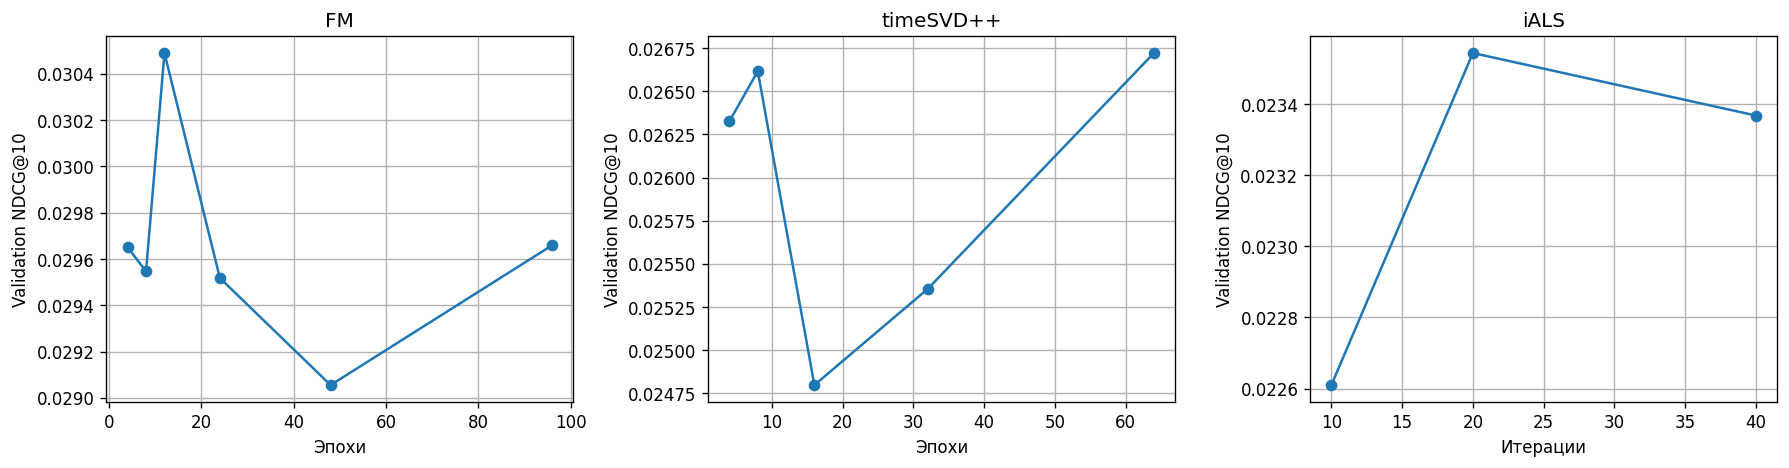

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, ['FM', 'timeSVD++', 'iALS']):
    parameter = 'iterations' if name == 'iALS' else 'epochs'
    reference = ({'factors': 16, 'regularization': 50.0} if name == 'iALS' else
        {'regularization': 1e-2, 'bin_days': 180} if name == 'timeSVD++' else
        {'feature_set': 'structured', 'target_mode': 'observed',
         'regularization': 1e-4, 'use_metadata': True})
    points = []
    for row in validation_rows:
        if row['model'] != name:
            continue
        params = json.loads(row['params'])
        if {k: v for k, v in params.items() if k != parameter} == reference:
            points.append((params[parameter], row['NDCG@10']))
    points.sort()
    ax.plot([p[0] for p in points], [p[1] for p in points], marker='o')
    ax.set(title=name, xlabel='Итерации' if name == 'iALS' else 'Эпохи', ylabel='Validation NDCG@10')
plt.tight_layout()
plt.show()


### Проверка вклада признаков и времени на validation

FM сравнивается с вариантами только на ID и на ID с агрегатами истории.
Это позволяет отдельно оценить вклад карточек товаров. Для timeSVD++ используется
статический SVD++ с той же неявной историей, но без временных компонентов.
У сравнительных вариантов те же настройки, которые выбраны для основной модели;
отдельный подбор для них не проводится.

Следующие таблицы относятся к validation: обучение выполнено только на train, в оценке 12 747 пользователей. Результаты test приведены отдельно в разделе 5.


In [12]:
fm_id_params = {**best_params['FM'], 'use_metadata': False}
fm_id = fit_model('FM', fm_id_params)
fm_history = fit_fm(best_params['FM'], historical_item_features)
display(pd.DataFrame([
    {'variant': 'FM: только ID', **evaluate(fm_id, valid_truth, X)},
    {'variant': 'FM: ID + агрегаты', **evaluate(fm_history, valid_truth, X)},
    {'variant': 'FM: ID + агрегаты + карточки', **evaluate(best_models['FM'], valid_truth, X)}]))
static_svd = TimeSVDPlusPlus(**best_params['timeSVD++'], temporal=False).fit(train, X, TRAIN_END)
display(pd.DataFrame([
    {'variant': 'Статический SVD++', **evaluate(static_svd, valid_truth, X)},
    {'variant': 'timeSVD++', **evaluate(best_models['timeSVD++'], valid_truth, X)}]))

validation_references = pd.DataFrame([
    {'model': 'Popularity', **evaluate(PopularityBaseline().fit(X), valid_truth, X)},
    {'model': 'Random expectation', **random_expected_metrics(valid_truth, X)}])
display(validation_references)

,variant,NDCG@10,Recall@10,users
0,FM: только ID,0.029083,0.034471,12747
1,FM: ID + агрегаты,0.028813,0.033620,12747
2,FM: ID + агрегаты + карточки,0.030490,0.037676,12747


,variant,NDCG@10,Recall@10,users
0,Статический SVD++,0.025973,0.027048,12747
1,timeSVD++,0.026722,0.029935,12747


,model,NDCG@10,Recall@10,users
0,Popularity,0.028950,0.034231,12747
1,Random expectation,0.001071,0.002003,12747


**Разбор validation.** Полная FM с карточками лучше вариантов только с ID
и с агрегатами истории по обеим метрикам. Агрегаты без карточек, наоборот,
немного ухудшили результат относительно ID. Временная модель timeSVD++
также превзошла статический SVD++ по обеим метрикам. Таким образом,
на validation добавление карточек и временных компонентов оказалось полезным
при фиксированных настройках. Ниже проверяется, сохраняется ли этот эффект на test.


## 5. Результаты на test

Выбранные настройки фиксируются, модели заново обучаются на train+validation.
Ниже приведены общая таблица результатов при K=10, выбранные параметры
и сравнения для FM и timeSVD++.

Для ориентира добавлены популярные товары по числу прошлых взаимодействий
и математическое ожидание случайного top-10. Для них используются те же
пользователи, кандидаты и исключения известных товаров. Время обучения зависит
от оборудования и приводится отдельно от качества.


,model,params,final_fit_seconds,validation_fit_seconds,eval_seconds,NDCG@10,Recall@10,users
0,EASE,"{""regularization"": 5000}",2.646099,2.441894,9.565522,0.060074,0.067154,11795
1,FM,"{""feature_set"": ""structured"", ""target_mode"": ""observed"", ""epochs"": 12, ""regularization"": 0.0001, ""use_metadata"": true}",9.922384,8.358623,4.915681,0.053643,0.054855,11795
2,timeSVD++,"{""epochs"": 64, ""regularization"": 0.01, ""bin_days"": 180}",259.370098,185.502989,4.695533,0.051975,0.051528,11795
3,ItemKNN,"{""neighbors"": 300, ""shrinkage"": 50}",1.310854,1.126757,3.681989,0.032322,0.052574,11795
4,iALS,"{""factors"": 16, ""regularization"": 50.0, ""iterations"": 20}",9.353118,7.047150,4.905783,0.030006,0.042098,11795


,model,NDCG@10,Recall@10,users
0,FM IDs only,0.053432,0.055826,11795
1,FM history only,0.053347,0.055228,11795
2,Static SVD++,0.052081,0.051577,11795


,model,NDCG@10,Recall@10,users
0,Popularity,0.053211,0.054763,11795
1,Random expectation,0.001079,0.002003,11795


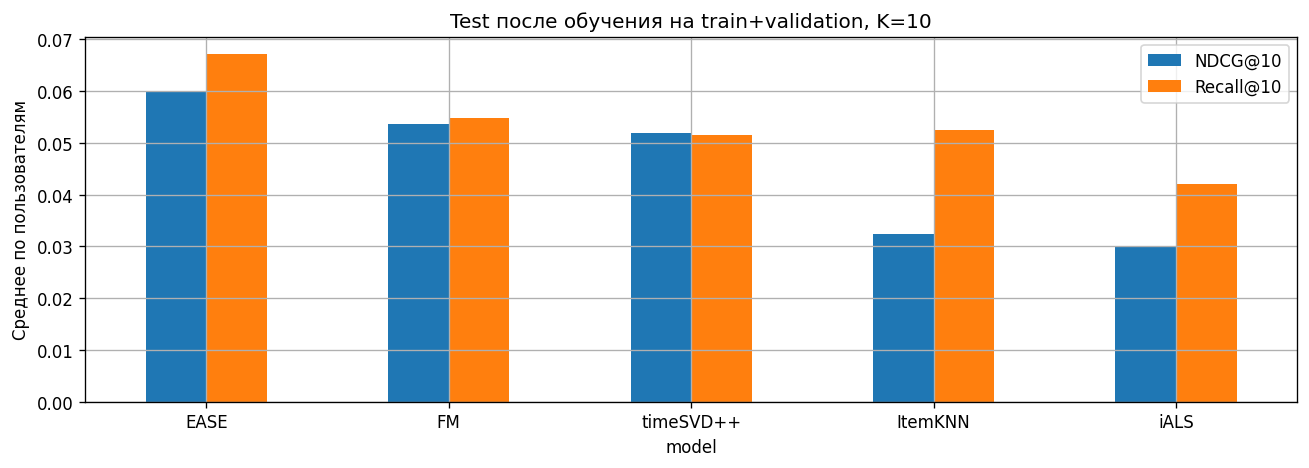

In [13]:
final_training = pd.concat([train, valid]).sort_values(['timestamp', 'u', 'i'], kind='stable')
final_context = make_training_context(final_training, VALID_END)
assert (final_context['X'] != seen_test).nnz == 0
assert final_training.timestamp.max() < test.timestamp.min()
final_models, test_rows, test_details = {}, [], {}
for name in best_models:
    started = time.perf_counter()
    model = fit_model(name, best_params[name], final_context)
    fit_seconds = time.perf_counter() - started
    final_models[name] = model
    started = time.perf_counter()
    metrics, test_details[name] = evaluate(model, test_truth, seen_test, return_per_user=True)
    validation_fit_seconds = validation_table[(validation_table.model == name) &
        (validation_table.params == json.dumps(best_params[name]))].iloc[0].fit_seconds
    test_rows.append({'model': name, 'params': json.dumps(best_params[name]),
        'final_fit_seconds': fit_seconds, 'validation_fit_seconds': validation_fit_seconds,
        'eval_seconds': time.perf_counter() - started, **metrics})
test_table = pd.DataFrame(test_rows).sort_values('NDCG@10', ascending=False).reset_index(drop=True)
with pd.option_context('display.max_colwidth', None, 'display.max_columns', None):
    display(test_table)
final_fm_id = fit_model('FM', fm_id_params, final_context)
final_fm_history = fit_fm(best_params['FM'], final_context['historical_item_features'], final_context)
final_static_svd = TimeSVDPlusPlus(**best_params['timeSVD++'], temporal=False).fit(
    final_training, final_context['X'], VALID_END)
ablation_test = pd.DataFrame([
    {'model': 'FM IDs only', **evaluate(final_fm_id, test_truth, seen_test)},
    {'model': 'FM history only', **evaluate(final_fm_history, test_truth, seen_test)},
    {'model': 'Static SVD++', **evaluate(final_static_svd, test_truth, seen_test)}])
display(ablation_test)
popular_metrics, popular_details = evaluate(PopularityBaseline().fit(seen_test),
    test_truth, seen_test, return_per_user=True)
baseline_test = pd.DataFrame([
    {'model': 'Popularity', **popular_metrics},
    {'model': 'Random expectation', **random_expected_metrics(test_truth, seen_test)}])
display(baseline_test)
ax = test_table.set_index('model')[['NDCG@10', 'Recall@10']].plot.bar(title='Test после обучения на train+validation, K=10')
ax.set_ylabel('Среднее по пользователям'); ax.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()
assert test_table.users.nunique() == 1
assert ((test_table[['NDCG@10', 'Recall@10']] >= 0) & (test_table[['NDCG@10', 'Recall@10']] <= 1)).all().all()

### Что показывают сравнения на test

Ниже разбираются результаты **test** после обучения на train+validation;
в оценке 11 795 пользователей.

**Популярность и случайные рекомендации.** На test все пять моделей заметно превосходят
случайный top-10. Значит, по данным можно находить релевантные товары лучше случайного
выбора. Но Popularity тоже намного лучше случайности: для этого достаточно знать,
какие товары чаще встречались в прошлых взаимодействиях. Поэтому пользу персональных
моделей оцениваем прежде всего относительно популярности.

EASE превзошёл Popularity по обеим метрикам. Полная FM почти совпала с ней,
а timeSVD++, ItemKNN и iALS уступили по обеим метрикам. В этом эксперименте
усложнение модели само по себе не обеспечило более полезные рекомендации.

**Признаки FM.** `FM IDs only` использует только ID пользователей и товаров.
`FM history only` добавляет активность, среднюю оценку и давность взаимодействий,
но не карточки товаров. Основная FM дополнительно использует магазин и категорию.
У всех трёх вариантов одинаковые выбранные настройки и обучающая цель.

На test добавление агрегатов истории не улучшило ни одну из метрик относительно варианта
только с ID. Карточки немного повысили NDCG по сравнению с вариантом на агрегатах,
но снизили Recall. Среди вариантов FM наибольший Recall остался у `FM IDs only`,
а наибольший NDCG — у полной FM. Поэтому согласованного улучшения от дополнительных
признаков на test не получилось. Эти варианты не проходили отдельный подбор,
поэтому сравнение показывает вклад признаков при фиксированных настройках.

**Время в SVD++.** `Static SVD++` использует ту же неявную историю, что и timeSVD++,
но без временных смещений и изменений факторов пользователя. При одинаковых
настройках статический вариант оказался на test немного лучше по обеим метрикам.
Разница мала: улучшения на test от временных компонентов в этом запуске не получено.
Это не означает, что они не нужны на других данных. В нашей постановке история
короткая, а рекомендации рассчитываются на начало длительного периода без обновлений.
Эти условия могут ограничивать пользу временной модели, но отдельно это не проверялось.

**Сопоставление с validation.** Направление эффекта дополнительных компонентов
не всегда сохранилось на test:

| Сравнение | Validation | Test |
|---|---|---|
| FM: агрегаты против только ID | Обе метрики ниже | Обе метрики ниже |
| FM: карточки против ID с агрегатами | Обе метрики выше | NDCG выше, Recall ниже |
| timeSVD++ против статического SVD++ | Обе метрики выше | Обе метрики немного ниже |

На validation карточки и временные компоненты помогли при выбранных настройках,
но их преимущество не подтвердилось по обеим метрикам на test. Между этими
оценками меняются период, состав оцениваемых пользователей и обучающая история:
для test модели обучаются заново на train+validation. Поэтому результаты могут
различаться. Определить причину изменения эффекта по одному разбиению нельзя.


## 6. Выводы

Лучший результат на test показал EASE с регуляризацией 5000. По сравнению с популярностью
его NDCG@10 выше примерно на 12,9%, Recall@10 — на 22,6%. Среди проверенных вариантов
лучше всего сработала линейная модель связей между товарами.

На test популярность оказалась сильным простым решением. FM получила близкий результат,
timeSVD++, ItemKNN и iALS уступили популярности. Возможные причины — выбранный популярный каталог
и небольшие пользовательские истории. Точную причину разницы между методами
по одному эксперименту установить нельзя.

Вывод о дополнительных компонентах зависит от части данных. На validation
карточки FM улучшили обе метрики относительно варианта с агрегатами истории,
а timeSVD++ превзошёл статический SVD++. На test у карточек сохранилось небольшое
преимущество по NDCG, но Recall снизился; timeSVD++ немного уступил статическому
варианту по обеим метрикам. Поэтому в итоговом сравнении на test однозначного
выигрыша от карточек и временных компонентов не получено. Агрегаты истории FM
не улучшили вариант только с ID ни на validation, ни на test.

Проверка более длинного обучения показала, что большее число проходов не всегда
полезно. Для FM лучшими остались 12 эпох, для iALS выбраны 20 итераций.
Для timeSVD++ лучший из проверенных вариантов — 64 эпохи, но выигрыш на validation
относительно 8 эпох небольшой. Поскольку это верхняя граница поиска,
дальнейшее улучшение не исключается.

Таким образом, в этой задаче EASE оказался предпочтительнее более сложных моделей.
Вывод относится к выбранной группе пользователей, каталогу и временной схеме.
Ограничения эксперимента перечислены ниже.


### Ограничения

- Оцениваются активные пользователи и популярный каталог из 5000 товаров.
  Новые пользователи, новые товары и короткие истории не исследуются.
- Официальный 5-core сформирован авторами по всей истории. Наш дополнительный
  отбор использует только train, но исходное ограничение выборки остаётся.
- Карточки взяты из снимка 2023 года без истории изменений. Магазин, название
  и категории считаются постоянными описаниями товара. Их состояние на начало
  train нельзя полностью подтвердить. Карточки с известной датой появления
  не раньше границы обучения отключаются; дата с неизвестным значением
  не используется как числовой признак. Накопленные рейтинги и число отзывов исключены.
- Отсутствие отзыва не означает, что товар не нравится. Среди выбранных
  отрицательных примеров могут быть товары, которые пользователь оценил бы положительно.
- На протяжении test модель и история фиксируются на 12.01.2021.
  Изменение интересов со временем может снижать качество.
- Использованы одна временная схема, одно случайное зерно и ограниченная сетка
  параметров. Результаты не оценивают разброс при повторном обучении.
